# Setup

In [1]:
!pip install numpyro

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 388.0/388.0 kB 26.1 MB/s eta 0:00:00


# Libraries

In [2]:
from pathlib import Path
from typing import Union

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

import numpyro
import numpyro.distributions as dist
from numpyro.infer import MCMC, NUTS, log_likelihood
import jax
import jax.numpy as jnp
import numpy as np
import arviz as az

import csv
import json

jax.config.update("jax_platforms", "cpu")
numpyro.set_host_device_count(4)
plt.style.use("bmh")


# Data Loading and Preprocessing

In [3]:
df = pd.read_csv("bml-component-data.csv")


In [4]:
covariate_cols = ["X1", "X2", "X3", "X4", "X5"]
component_data = (
    df.groupby("index")[covariate_cols + ["ID"]]
    .first()
    .sort_index()
)

X = component_data[covariate_cols].values
component_ids = component_data["ID"].values

n_components = 75
t_all = []
y_all = []


for i in range(n_components):
    rows = df[df["index"] == i].sort_values("day")
    t_all.append(rows["day"].values.astype(float))
    y_all.append(rows["integrity"].values.astype(float))

train_idx = list(range(50))
test_idx = list(range(50, 75))

t_train = [t_all[i] for i in train_idx]
y_train = [y_all[i] for i in train_idx]
t_test = [t_all[i] for i in test_idx]
X_train = X[train_idx]


print(f"Total observations: {len(df)}")
print(f"Train obs: {sum(len(t) for t in t_train)} across {len(train_idx)} components")
print(f"Test obs: {sum(len(t) for t in t_test)} across {len(test_idx)} components")
display(pd.DataFrame(X, columns=covariate_cols).describe().drop(["count"]).round(3))

days_to_predict = jnp.linspace(0.0, 60.0, 200)
components_of_interest = [0, 51, 61, 71]


Total observations: 879
Train obs: 805 across 50 components
Test obs: 74 across 25 components


,X1,X2,X3,X4,X5
mean,1.555,1.918,1.478,2.020,1.648
std,1.582,2.454,1.420,3.005,2.035
min,0.140,0.044,0.078,0.162,0.123
25%,0.617,0.676,0.440,0.486,0.414
50%,1.062,1.177,0.900,1.109,0.984
75%,1.917,1.975,2.012,1.972,2.069
max,9.175,15.516,6.821,14.272,12.921


# Baseline Model

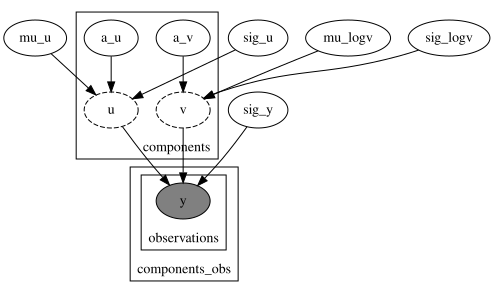

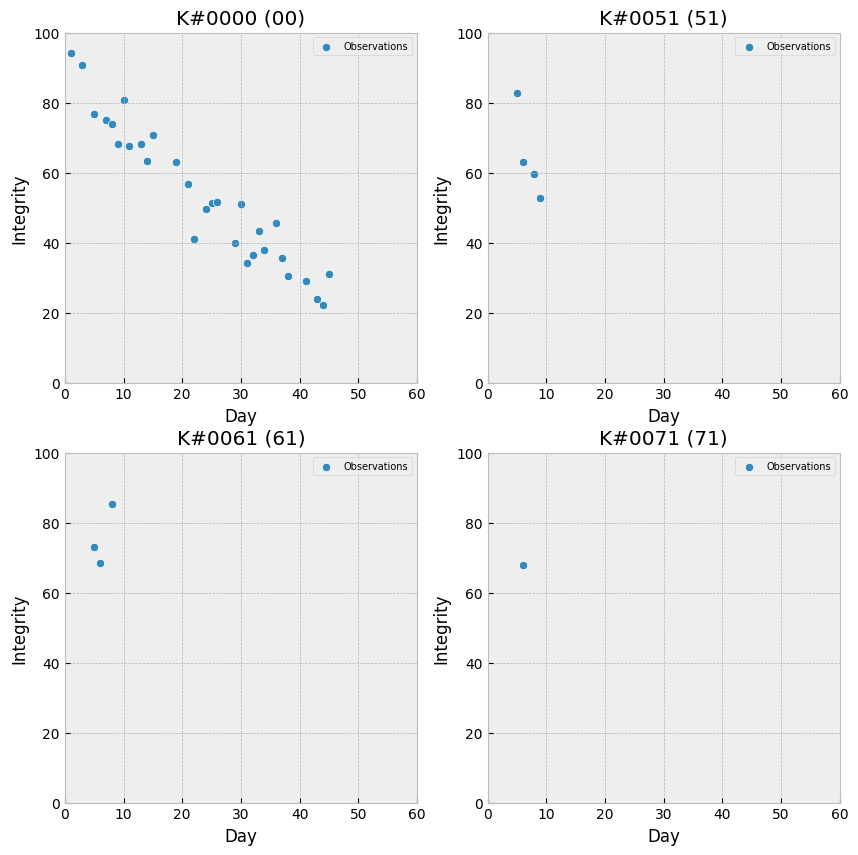

In [5]:
def view_component(identifier, ax):
    idx = identifier
    x = t_all[idx]
    y = y_all[idx]
    sns.scatterplot(x=x, y=y, ax=ax, label="Observations")
    ax.set_title(f"K#{identifier:04d} ({idx:02d})")
    ax.set_xlabel("Day")
    ax.set_ylabel("Integrity")
    ax.set_xlim(0.0, 60.0)
    ax.set_ylim(0.0, 100.0)
    ax.legend(fontsize=7)


def view_component_prediction(identifier, pred_mean, pred_std, pred_std_noiseless, ax):
    view_component(identifier, ax)
    t = np.array(days_to_predict)
    m = np.array(pred_mean)
    ax.plot(t, m, color="Firebrick", label="Posterior mean")
    ax.fill_between(t, m - 1.96 * np.array(pred_std), m + 1.96 * np.array(pred_std),
                    alpha=0.2, color="Firebrick", label="95% predictive interval")
    ax.fill_between(t, m - 1.96 * np.array(pred_std_noiseless), m + 1.96 * np.array(pred_std_noiseless),
                    alpha=0.4, color="Firebrick", label="95% function interval")
    ax.set_xlim(0.0, 60.0)
    ax.set_ylim(0.0, 100.0)
    ax.legend(fontsize=7)


_, ax4 = plt.subplots(2, 2, figsize=(10, 10))
for plot_pos, idx in enumerate(components_of_interest):
    view_component(idx, ax4.ravel()[plot_pos])


def pad_ragged(arrays, pad_value=0.0):
    n = len(arrays)
    max_len = max(len(a) for a in arrays)
    padded = np.full((n, max_len), pad_value, dtype=float)
    mask = np.zeros((n, max_len), dtype=bool)
    for i, a in enumerate(arrays):
        padded[i, :len(a)] = a
        mask[i, :len(a)] = True

    return padded, mask


t_pad, mask_train = pad_ragged(t_train)
y_pad, _ = pad_ragged(y_train)

t_pad = jnp.array(t_pad)
y_pad = jnp.array(y_pad)
mask_train = jnp.array(mask_train)


t_all_pad, mask_all = pad_ragged(t_all)
y_all_pad, _ = pad_ragged(y_all)

t_all_jnp = jnp.array(t_all_pad)
y_all_jnp = jnp.array(y_all_pad)
mask_all_jnp = jnp.array(mask_all)
X_all_jnp = jnp.array(X)


def baseline_model(t_obs, y_obs, mask):
    n_comp = t_obs.shape[0]

    mu_u = numpyro.sample("mu_u", dist.Normal(90.0, 10.0))
    sig_u = numpyro.sample("sig_u", dist.HalfNormal(5.0))
    mu_logv = numpyro.sample("mu_logv", dist.Normal(1.6, 1.0))
    sig_logv = numpyro.sample("sig_logv", dist.HalfNormal(0.5))
    sig_y = numpyro.sample("sig_y", dist.HalfNormal(10.0))

    with numpyro.plate("components", n_comp):
        a_u = numpyro.sample("a_u", dist.Normal(0.0, 1.0))
        u = numpyro.deterministic("u", mu_u + a_u * sig_u)
        a_v = numpyro.sample("a_v", dist.Normal(0.0, 1.0))
        v = numpyro.deterministic("v", jnp.exp(mu_logv + a_v * sig_logv))

    f = u[:, None] * jnp.exp(-v[:, None] * t_obs / 100.0)

    with numpyro.plate("components_obs", n_comp, dim=-2):
        with numpyro.plate("observations", t_obs.shape[1], dim=-1):
            numpyro.sample("y", dist.Normal(f, sig_y).mask(mask), obs=y_obs)


numpyro.render_model(baseline_model, model_args=(t_pad, y_pad, mask_train),
                     render_params=True, filename="baseline_model.png")


  0%|          | 0/4000 [00:00<?, ?it/s]

  0%|          | 0/4000 [00:00<?, ?it/s]

  0%|          | 0/4000 [00:00<?, ?it/s]

  0%|          | 0/4000 [00:00<?, ?it/s]


                mean       std    median      5.0%     95.0%     n_eff     r_hat
    a_u[0]      0.82      0.47      0.82      0.06      1.60  10381.55      1.00
    a_u[1]     -0.53      0.82     -0.53     -1.88      0.81  10878.35      1.00
    a_u[2]      1.70      0.47      1.68      0.95      2.49   9490.12      1.00
    a_u[3]     -0.10      0.43     -0.09     -0.82      0.60  10121.67      1.00
    a_u[4]     -0.43      0.74     -0.44     -1.62      0.83  12388.17      1.00
    a_u[5]     -0.06      0.79     -0.06     -1.40      1.17  11676.88      1.00
    a_u[6]      0.32      0.71      0.32     -0.82      1.50  10934.89      1.00
    a_u[7]     -0.80      0.76     -0.80     -2.04      0.45  12132.68      1.00
    a_u[8]      0.02      0.70      0.02     -1.10      1.18   9740.21      1.00
    a_u[9]     -0.78      0.78     -0.78     -2.10      0.46  10866.48      1.00
   a_u[10]     -0.85      0.57     -0.85     -1.85      0.04  10821.82      1.00
   a_u[11]     -0.41      0

,mean,sd,hdi_5%,hdi_95%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
mu_u,89.750,0.957,88.193,91.351,0.014,0.011,4669.720,5510.953,1.000
sig_u,5.233,0.849,3.871,6.615,0.013,0.009,3915.486,5601.645,1.001
mu_logv,1.312,0.056,1.224,1.408,0.002,0.001,1400.636,2196.025,1.003
sig_logv,0.367,0.042,0.298,0.433,0.001,0.001,2456.565,3608.901,1.000
sig_y,5.038,0.133,4.826,5.264,0.001,0.001,8915.594,5974.827,1.000


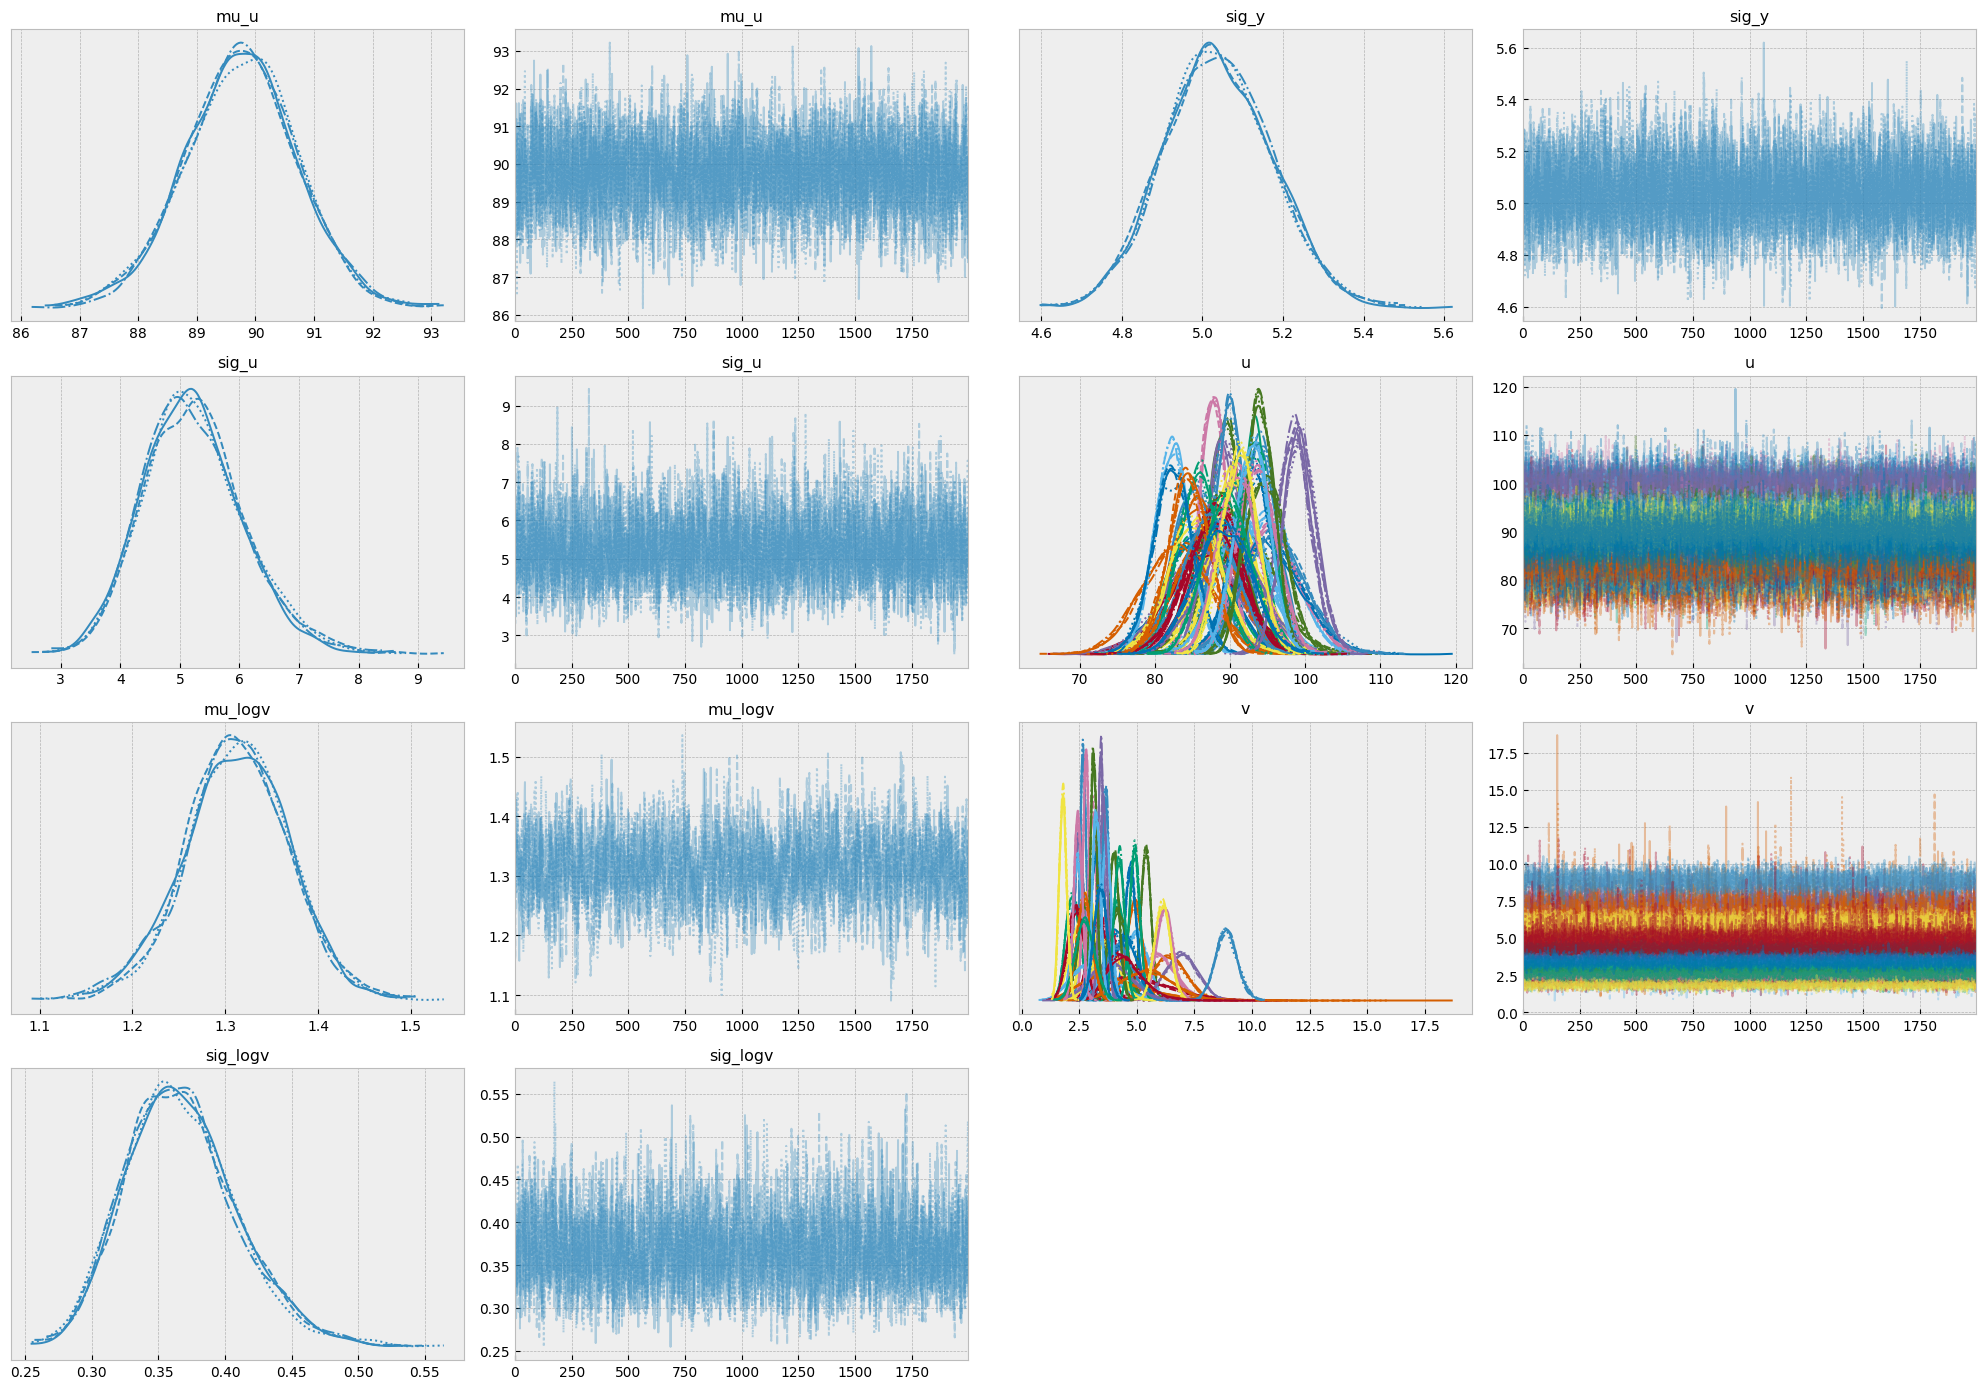

In [6]:
debugger = False
num_samples = 200 if debugger else 2000
num_warmup = 100 if debugger else 2000

seed = 0
mcmc_baseline = MCMC(NUTS(baseline_model), num_samples=num_samples, num_warmup=num_warmup, num_chains=4)
mcmc_baseline.run(jax.random.PRNGKey(seed), t_pad, y_pad, mask_train)
mcmc_baseline.print_summary()

data_baseline = az.from_numpyro(mcmc_baseline)

display(az.summary(data_baseline, var_names=["mu_u", "sig_u", "mu_logv", "sig_logv", "sig_y"], round_to=3, hdi_prob=0.90))

fig, axes = plt.subplots(4, 4, figsize=(20, 14))
left_vars  = ["mu_u", "sig_u", "mu_logv", "sig_logv"]
right_vars = ["sig_y", "u", "v"]

az.plot_trace(data_baseline, compact=True, var_names=left_vars, axes=axes[:, :2])
az.plot_trace(data_baseline, compact=True, var_names=right_vars, axes=axes[:3, 2:])

axes[3, 2].set_visible(False)
axes[3, 3].set_visible(False)

fig.tight_layout()
plt.show()


# Baseline fit

  0%|          | 0/4000 [00:00<?, ?it/s]

  0%|          | 0/4000 [00:00<?, ?it/s]

  0%|          | 0/4000 [00:00<?, ?it/s]

  0%|          | 0/4000 [00:00<?, ?it/s]

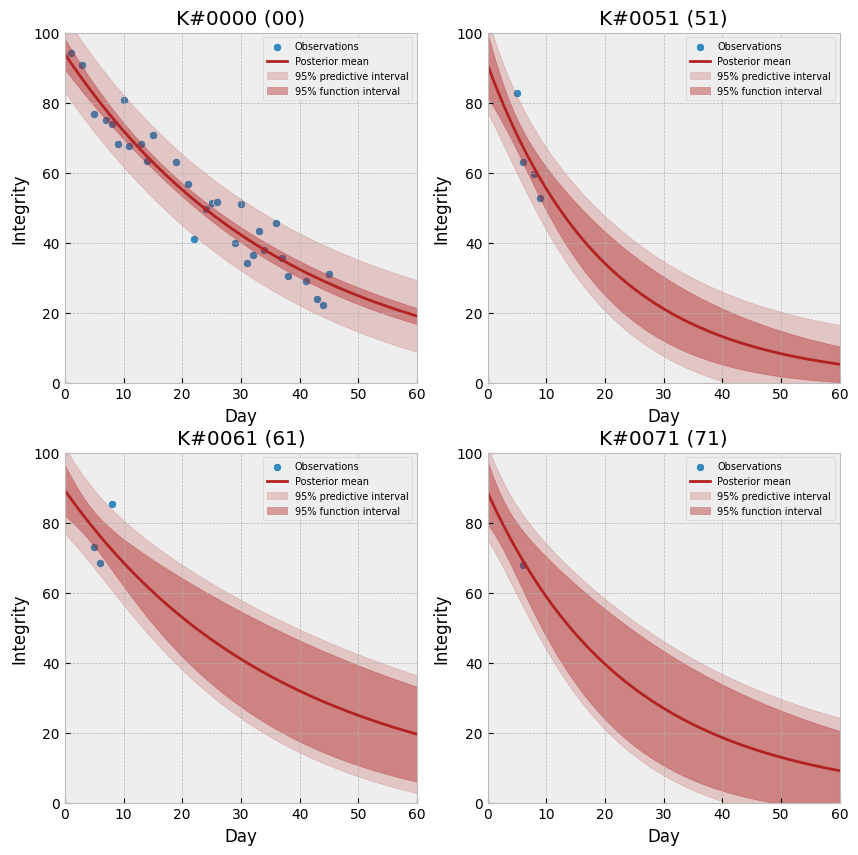

In [7]:
samples_baseline = mcmc_baseline.get_samples()

def predict(component, mcmc_samples, t):
    pred_idx = component
    u_s = mcmc_samples["u"][:, pred_idx]
    v_s = mcmc_samples["v"][:, pred_idx]
    Y = u_s[:, None] * jnp.exp(-v_s[:, None] * t / 100.0)
    f_mean = jnp.mean(Y, axis=0)
    f_var = jnp.var(Y, axis=0)
    f_std_noiseless = jnp.sqrt(f_var)
    noise_var = jnp.mean(mcmc_samples["sig_y"] ** 2)
    f_std = jnp.sqrt(f_var + noise_var)

    return f_mean, f_std, f_std_noiseless


mcmc_baseline_full = MCMC(NUTS(baseline_model), num_samples=num_samples, num_warmup=num_warmup, num_chains=4)
mcmc_baseline_full.run(jax.random.PRNGKey(seed + 3), t_all_jnp, y_all_jnp, mask_all_jnp)
samples_baseline_full = mcmc_baseline_full.get_samples()


_, ax4 = plt.subplots(2, 2, figsize=(10, 10))
for plot_pos, idx in enumerate(components_of_interest):
    pred_mean, pred_std, pred_std_noiseless = predict(idx, samples_baseline_full, days_to_predict)
    view_component_prediction(idx, pred_mean, pred_std, pred_std_noiseless, ax4.ravel()[plot_pos])


# Enhanced Model

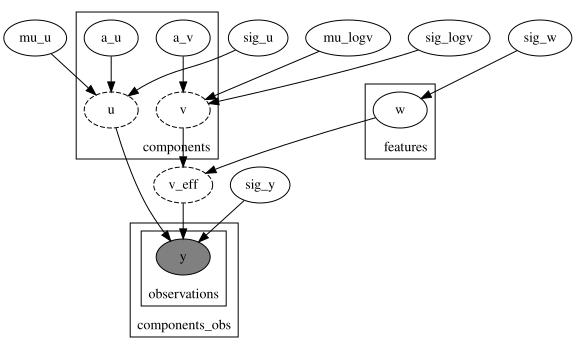

In [8]:
X_train_jnp = jnp.array(X_train)

def enhanced_model(t_obs, y_obs, mask, X_comp):
    n_comp, n_feat = X_comp.shape

    mu_u = numpyro.sample("mu_u", dist.Normal(90.0, 10.0))
    sig_u = numpyro.sample("sig_u", dist.HalfNormal(5.0))
    mu_logv = numpyro.sample("mu_logv", dist.Normal(1.6, 1.0))
    sig_logv = numpyro.sample("sig_logv", dist.HalfNormal(0.5))
    sig_y = numpyro.sample("sig_y", dist.HalfNormal(10.0))
    sig_w = numpyro.sample("sig_w", dist.HalfNormal(1.0))

    with numpyro.plate("features", n_feat):
        w = numpyro.sample("w", dist.Normal(0.0, sig_w))

    with numpyro.plate("components", n_comp):
        a_u = numpyro.sample("a_u", dist.Normal(0., 1.0))
        u = numpyro.deterministic("u", mu_u + a_u * sig_u)
        a_v = numpyro.sample("a_v", dist.Normal(0., 1.0))
        v = numpyro.deterministic("v", jnp.exp(mu_logv + a_v * sig_logv))

    covariate_contribution = X_comp @ w
    v_eff = numpyro.deterministic("v_eff", v + covariate_contribution)

    f = u[:, None] * jnp.exp(-v_eff[:, None] * t_obs / 100.0)

    with numpyro.plate("components_obs", n_comp, dim=-2):
        with numpyro.plate("observations", t_obs.shape[1], dim=-1):
            numpyro.sample("y", dist.Normal(f, sig_y).mask(mask), obs=y_obs)


numpyro.render_model(enhanced_model, model_args=(t_pad, y_pad, mask_train, X_train_jnp),
                     render_params=True, filename="enhanced_model.png")


  0%|          | 0/4000 [00:00<?, ?it/s]

  0%|          | 0/4000 [00:00<?, ?it/s]

  0%|          | 0/4000 [00:00<?, ?it/s]

  0%|          | 0/4000 [00:00<?, ?it/s]


                mean       std    median      5.0%     95.0%     n_eff     r_hat
    a_u[0]      0.83      0.47      0.82      0.05      1.60  11321.57      1.00
    a_u[1]      0.34      0.74      0.35     -0.83      1.55  12068.67      1.00
    a_u[2]      1.67      0.47      1.65      0.93      2.44   9458.51      1.00
    a_u[3]     -0.15      0.44     -0.16     -0.87      0.58  10399.53      1.00
    a_u[4]     -0.20      0.67     -0.21     -1.27      0.92  12340.78      1.00
    a_u[5]     -0.45      0.72     -0.44     -1.61      0.77  13280.57      1.00
    a_u[6]      0.21      0.60      0.20     -0.80      1.18  10672.47      1.00
    a_u[7]     -1.07      0.73     -1.07     -2.21      0.21  12827.00      1.00
    a_u[8]     -0.04      0.60     -0.04     -1.03      0.98   9712.65      1.00
    a_u[9]     -1.07      0.67     -1.08     -2.16      0.06  11096.71      1.00
   a_u[10]     -0.81      0.53     -0.80     -1.66      0.10   9616.24      1.00
   a_u[11]     -0.19      0

,mean,sd,hdi_5%,hdi_95%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
mu_u,90.177,0.921,88.688,91.727,0.012,0.009,5426.238,6069.715,1.001
sig_u,5.005,0.723,3.798,6.147,0.010,0.007,4789.969,6379.089,1.000
mu_logv,0.659,0.088,0.520,0.807,0.001,0.001,4644.004,4908.518,1.000
sig_logv,0.184,0.040,0.122,0.248,0.001,0.000,3915.629,5493.976,1.003
sig_y,5.041,0.131,4.828,5.250,0.001,0.001,11040.115,6299.158,1.000


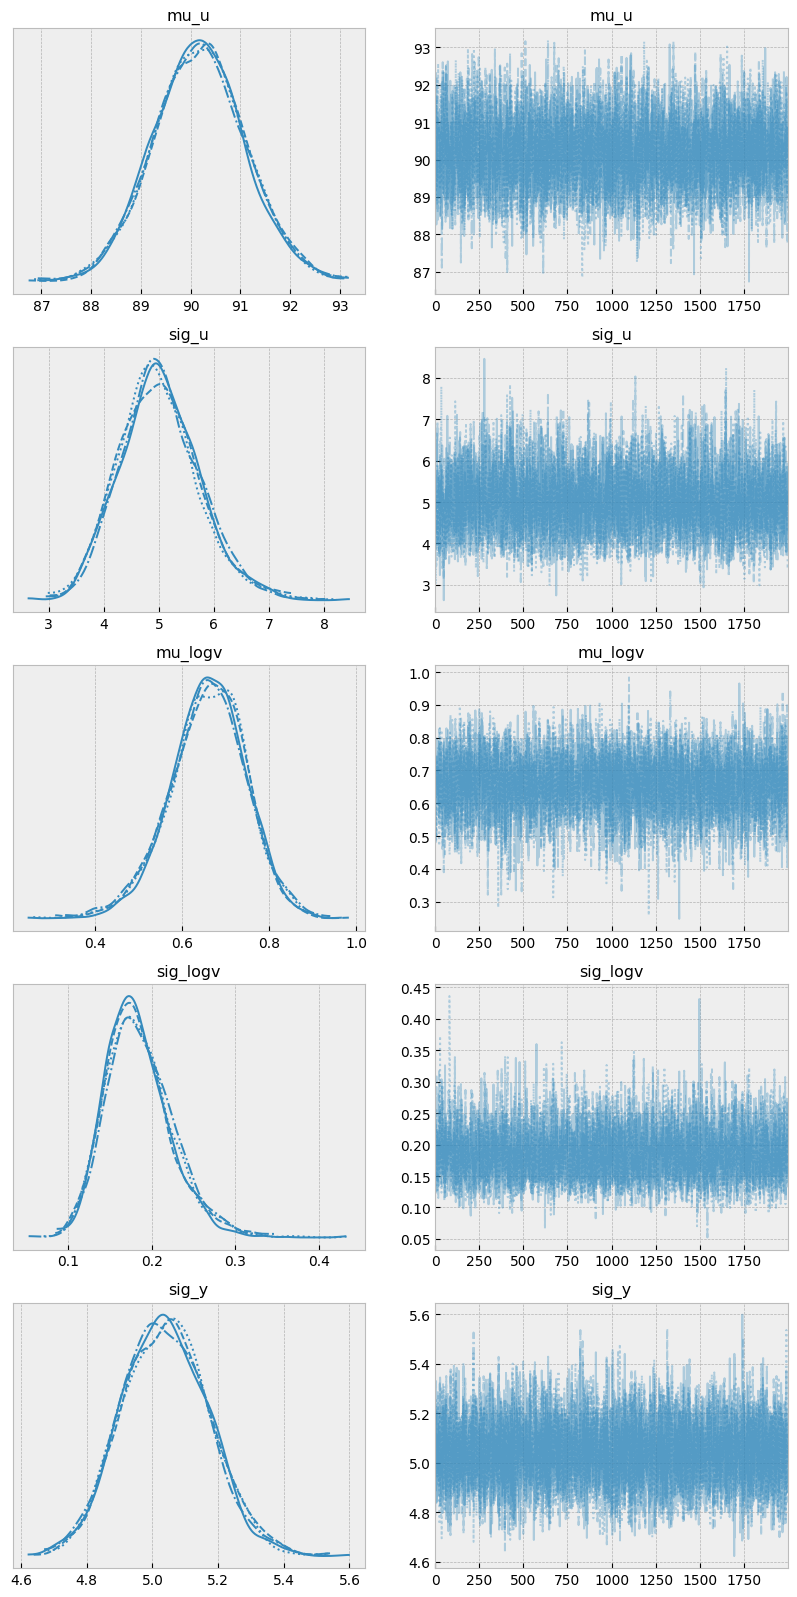

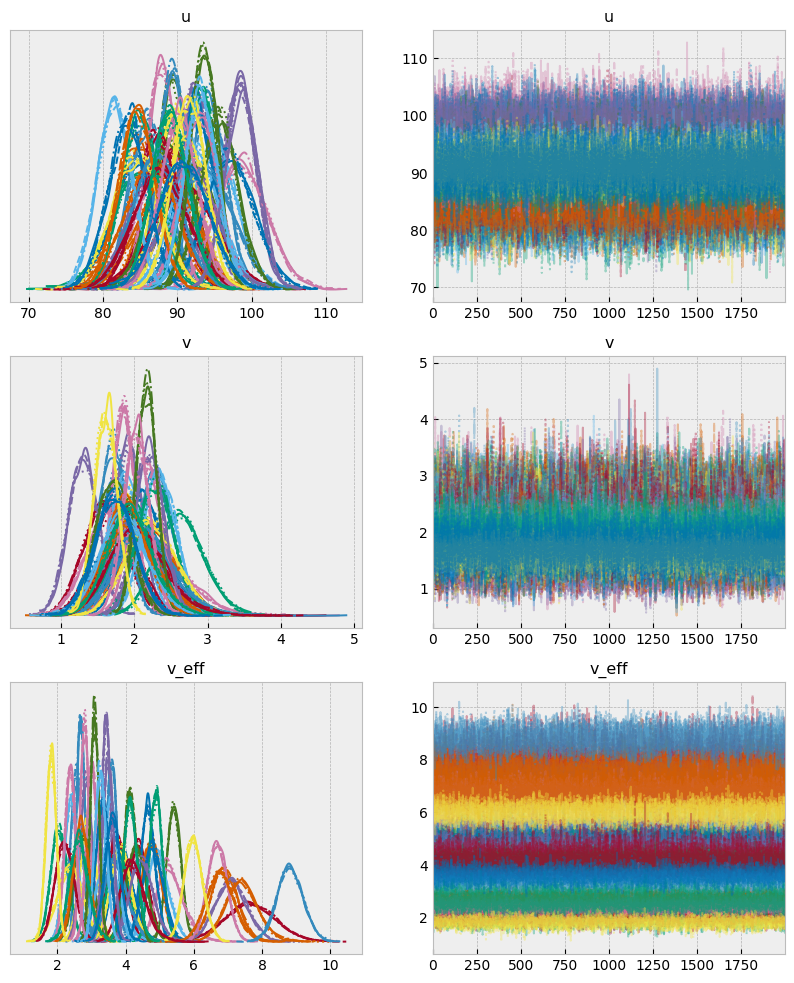

In [9]:
mcmc_enhanced = MCMC(NUTS(enhanced_model), num_samples=num_samples, num_warmup=num_warmup, num_chains=4)
mcmc_enhanced.run(jax.random.PRNGKey(seed + 1), t_pad, y_pad, mask_train, X_train_jnp)
mcmc_enhanced.print_summary()

data_enhanced = az.from_numpyro(mcmc_enhanced)


display(az.summary(data_enhanced, var_names=["mu_u", "sig_u", "mu_logv", "sig_logv", "sig_y"], hdi_prob=0.90, round_to=3))

az.plot_trace(data_enhanced, compact=True, figsize=(10, 20), var_names=["mu_u", "sig_u", "mu_logv", "sig_logv", "sig_y"])
plt.show()

az.plot_trace(data_enhanced, compact=True, figsize=(10, 12), var_names=["u", "v", "v_eff"])
plt.show()


samples_enhanced = mcmc_enhanced.get_samples()

def predict_enhanced(component, mcmc_samples, t):
    pred_idx = component
    u_s = mcmc_samples["u"][:, pred_idx]
    v_eff_s = mcmc_samples["v_eff"][:, pred_idx]
    Y = u_s[:, None] * jnp.exp(-v_eff_s[:, None] * t / 100.0)
    f_mean = jnp.mean(Y, axis=0)
    f_var = jnp.var(Y, axis=0)
    f_std_noiseless = jnp.sqrt(f_var)
    noise_var = jnp.mean(mcmc_samples["sig_y"] ** 2)
    f_std = jnp.sqrt(f_var + noise_var)

    return f_mean, f_std, f_std_noiseless


In [10]:
v_baseline = mcmc_baseline.get_samples()["v"]
v_enhanced = mcmc_enhanced.get_samples()["v"]

df = pd.DataFrame({
    "Model": ["Baseline", "Enhanced"],
    "Mean(v_i)": [float(v_baseline.mean()), float(v_enhanced.mean())],
    "Std(v_i)": [float(v_baseline.std()),  float(v_enhanced.std())],
}).set_index("Model").round(3)

display(df)

,Mean(v_i),Std(v_i)
Model,,
Baseline,3.962,1.493
Enhanced,1.971,0.384


# Enhanced Fit

In [11]:
mcmc_full = MCMC(NUTS(enhanced_model), num_samples=num_samples, num_warmup=num_warmup, num_chains=4)
mcmc_full.run(jax.random.PRNGKey(seed + 2), t_all_jnp, y_all_jnp, mask_all_jnp, X_all_jnp)
mcmc_full.print_summary()

data_full = az.from_numpyro(mcmc_full)
samples_full = mcmc_full.get_samples()


  0%|          | 0/4000 [00:00<?, ?it/s]

  0%|          | 0/4000 [00:00<?, ?it/s]

  0%|          | 0/4000 [00:00<?, ?it/s]

  0%|          | 0/4000 [00:00<?, ?it/s]


                mean       std    median      5.0%     95.0%     n_eff     r_hat
    a_u[0]      0.82      0.47      0.81      0.08      1.61   7827.87      1.00
    a_u[1]      0.35      0.75      0.35     -0.90      1.52   8209.30      1.00
    a_u[2]      1.69      0.47      1.67      0.93      2.46   7012.46      1.00
    a_u[3]     -0.24      0.46     -0.25     -0.97      0.52   7850.95      1.00
    a_u[4]     -0.16      0.69     -0.15     -1.30      0.97   9212.77      1.00
    a_u[5]     -0.48      0.75     -0.48     -1.71      0.71   9169.94      1.00
    a_u[6]      0.10      0.63      0.10     -0.90      1.16   8938.07      1.00
    a_u[7]     -1.14      0.76     -1.14     -2.42      0.07   9062.90      1.00
    a_u[8]     -0.10      0.61     -0.11     -1.09      0.91   6833.97      1.00
    a_u[9]     -1.11      0.68     -1.12     -2.23     -0.03   8570.30      1.00
   a_u[10]     -0.82      0.55     -0.81     -1.72      0.07   7399.03      1.00
   a_u[11]     -0.18      0

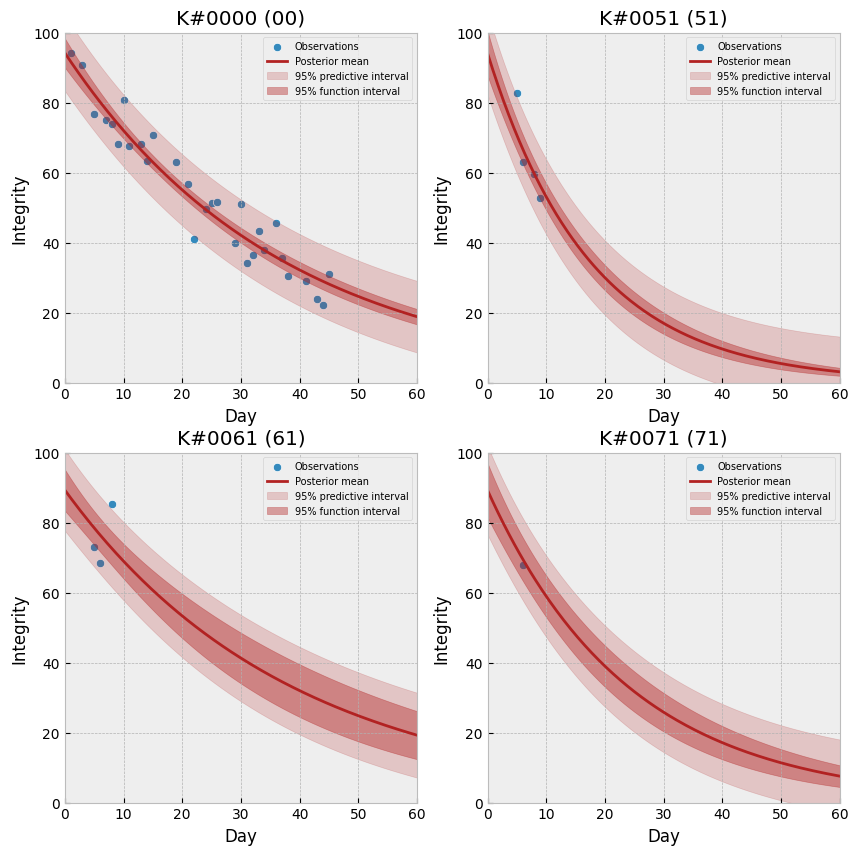

In [12]:
_, ax4 = plt.subplots(2, 2, figsize=(10, 10))
for plot_pos, idx in enumerate(components_of_interest):
    pred_mean, pred_std, pred_std_noiseless = predict_enhanced(idx, samples_full, days_to_predict)
    view_component_prediction(idx, pred_mean, pred_std, pred_std_noiseless, ax4.ravel()[plot_pos])


# Covariate weights

,mean,sd,hdi_5%,hdi_95%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
w[0],-0.044,0.059,-0.142,0.050,0.001,0.001,6776.995,6046.027,1.000
w[1],0.183,0.047,0.108,0.262,0.001,0.001,7931.419,5719.515,1.000
w[2],1.029,0.071,0.916,1.148,0.001,0.001,6476.411,6129.022,1.000
w[3],0.217,0.029,0.167,0.263,0.000,0.000,8401.816,5739.135,1.000
w[4],-0.021,0.048,-0.099,0.057,0.001,0.001,6472.856,6411.360,1.000
sig_w,0.597,0.226,0.298,0.907,0.003,0.005,12251.334,5542.114,1.001


array([[<Axes: title={'center': 'w'}>, <Axes: title={'center': 'w'}>],
       [<Axes: title={'center': 'sig_w'}>,
        <Axes: title={'center': 'sig_w'}>]], dtype=object)

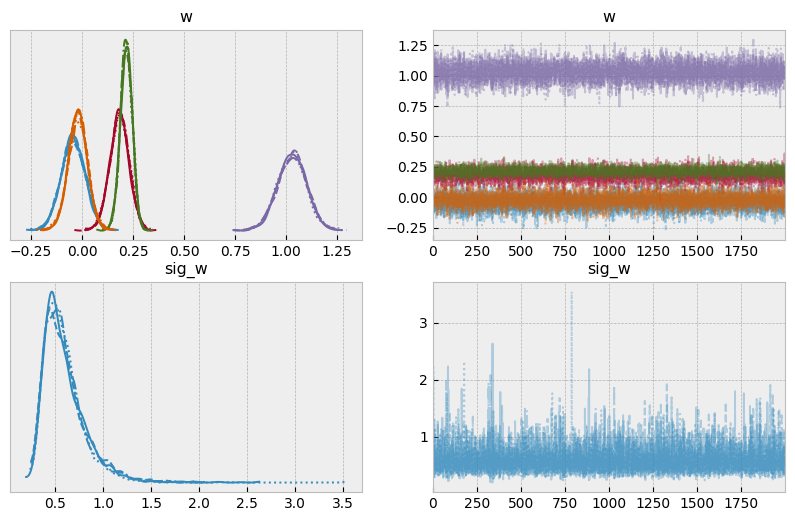

In [13]:
display(az.summary(data_enhanced, var_names=["w", "sig_w"], hdi_prob=0.90, round_to=3))

az.plot_trace(data_enhanced, compact=True, figsize=(10, 6), var_names=["w", "sig_w"])


# Blind Test Predictions

In [14]:
t_predict = 30.0
integrity_threshold = 30.0

f_at_30 = (samples_full["u"][:, 50:] * jnp.exp(-samples_full["v_eff"][:, 50:] * t_predict / 100.))
prob_below_30 = np.array(jnp.mean(f_at_30 < integrity_threshold, axis=0))

for k, global_idx in enumerate(test_idx):
    print(f"{component_ids[global_idx]}: n={len(t_all[global_idx])}"
          f"P(integrity<30 at t=30): {prob_below_30[k]:.4f}")

print(f"Mean P(below 30): {prob_below_30.mean():.4f}")
n_likely = int((prob_below_30 > 0.5).sum())
print(f"Components with P > 0.5 (likely below threshold): {n_likely} / 25")


output_rows = [
    {
        "ID": component_ids[global_idx],
        "index": global_idx,
        "probability": float(prob_below_30[k]),
    }
    for k, global_idx in enumerate(test_idx)
]

with open("predictions.csv", "w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=["ID", "index", "probability"])
    writer.writeheader()
    writer.writerows(output_rows)


K#0050: n=4P(integrity<30 at t=30): 0.1093
K#0051: n=4P(integrity<30 at t=30): 1.0000
K#0052: n=4P(integrity<30 at t=30): 1.0000
K#0053: n=5P(integrity<30 at t=30): 0.4051
K#0054: n=3P(integrity<30 at t=30): 0.0041
K#0055: n=1P(integrity<30 at t=30): 0.9128
K#0056: n=5P(integrity<30 at t=30): 0.9999
K#0057: n=4P(integrity<30 at t=30): 0.0001
K#0058: n=2P(integrity<30 at t=30): 1.0000
K#0059: n=2P(integrity<30 at t=30): 0.6476
K#0060: n=1P(integrity<30 at t=30): 0.2854
K#0061: n=3P(integrity<30 at t=30): 0.0025
K#0062: n=1P(integrity<30 at t=30): 0.0325
K#0063: n=4P(integrity<30 at t=30): 0.0006
K#0064: n=6P(integrity<30 at t=30): 0.0000
K#0065: n=1P(integrity<30 at t=30): 1.0000
K#0066: n=1P(integrity<30 at t=30): 1.0000
K#0067: n=1P(integrity<30 at t=30): 1.0000
K#0068: n=3P(integrity<30 at t=30): 0.0300
K#0069: n=1P(integrity<30 at t=30): 1.0000
K#0070: n=2P(integrity<30 at t=30): 0.9993
K#0071: n=1P(integrity<30 at t=30): 0.9331
K#0072: n=8P(integrity<30 at t=30): 0.0618
K#0073: n=3

# Save Hyperparameters

In [15]:
def extract_hyperparameters(samples):
    return {
        "mu_u": float(jnp.mean(samples["mu_u"])),
        "sig_u": float(jnp.mean(samples["sig_u"])),
        "mu_logv": float(jnp.mean(samples["mu_logv"])),
        "sig_logv": float(jnp.mean(samples["sig_logv"])),
        "sig_y": float(jnp.mean(samples["sig_y"])),
        "sig_w": float(jnp.mean(samples["sig_w"])),
        "w": np.array(jnp.mean(samples["w"], axis=0)).tolist()
    }

hyperparameters = extract_hyperparameters(samples_full)

with open("hyperparameters.json", "w") as f:
    json.dump(hyperparameters, f, indent=2)